In [4]:
%pip install numpy matplotlib scipy > /dev/null
%load_ext autoreload
%autoreload 2

import warnings
warnings.filterwarnings("ignore")

import kalman
kalman.set_debug(0)

import kalman.runtime.chrono as chrono
import numpy as np

Note: you may need to restart the kernel to use updated packages.
The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


# Suspension Dynamics & Thermal Noise

Two complementary suspension problems solved with the Kalman filter:

| Section | System | Model |
|---|---|---|
| 1 | Automotive quarter-car — state estimation from a single position sensor | `SuspensionModel` |
| 2 | Fiber thermal noise — violin modes + power-line harmonics jointly removed | `InharmonicOscillatorModel` |

## Section 1 — Quarter-Car Suspension

### Physical model

```
     ┌──────────────┐
     │  Sprung mass │  m_s = 300 kg  (¼ vehicle body)
     │     (z_s)    │
     └──┬──────┬───┘
       │ k_s  │ b_s      spring k_s = 20 kN/m,  damper b_s = 1.5 kN·s/m
     ┌──┴──────┴───┐
     │Unsprung mass│  m_u = 50 kg   (wheel + axle)
     │     (z_u)   │
     └──────┬──────┘
            │ k_t = 180 kN/m       tyre stiffness
            │ u(t)                 road displacement (control input)
```

State: $\mathbf{x} = [z_s,\; \dot{z}_s,\; z_u,\; \dot{z}_u]^\top$. Only $z_s$ is measured.  
The filter reconstructs all four states — including the unobserved wheel hub — from the single  
body-position sensor, exploiting full observability through the spring/damper coupling.

**Multi-rate**: EKF prediction at 1 kHz; displacement sensor at 100 Hz.  
Rows with `NaN` in the measurement vector trigger predict-only steps.

SuspensionModel(KalmanLinearModel) @ fs=1000.0Hz
    Quarter-Car Suspension Model (v1.0)
        Linear 2-DOF quarter-car suspension model. States:
        [z_s, dz_s, z_u, dz_u]. Observable: sprung
        displacement z_s. Control input: road
        displacement u.
    Dimensions Summary:
        State Vector....................................: 4 dims (SuspensionState<SPRUNG_DISP, SPRUNG_VEL, UNSPRUNG_DISP, UNSPRUNG_VEL>)
        Observation.....................................: 1 dim  (SuspensionObservable<SPRUNG_DISP>)
        Control Input...................................: 1 dim 
    Initial State:
        State Vector (x0)...............................: 4x1 dims
        State Covariance (P0)...........................: 4x4 dims
    Linear Model Structure (n=4, m=1, l=1):
        Jacobian Matrices:
            F (or A) (state transition      ) : 4x4 dims
            H (or C) (measurement map       ) : 1x4 dims
            B        (control map           ) : 4x1 dims
         

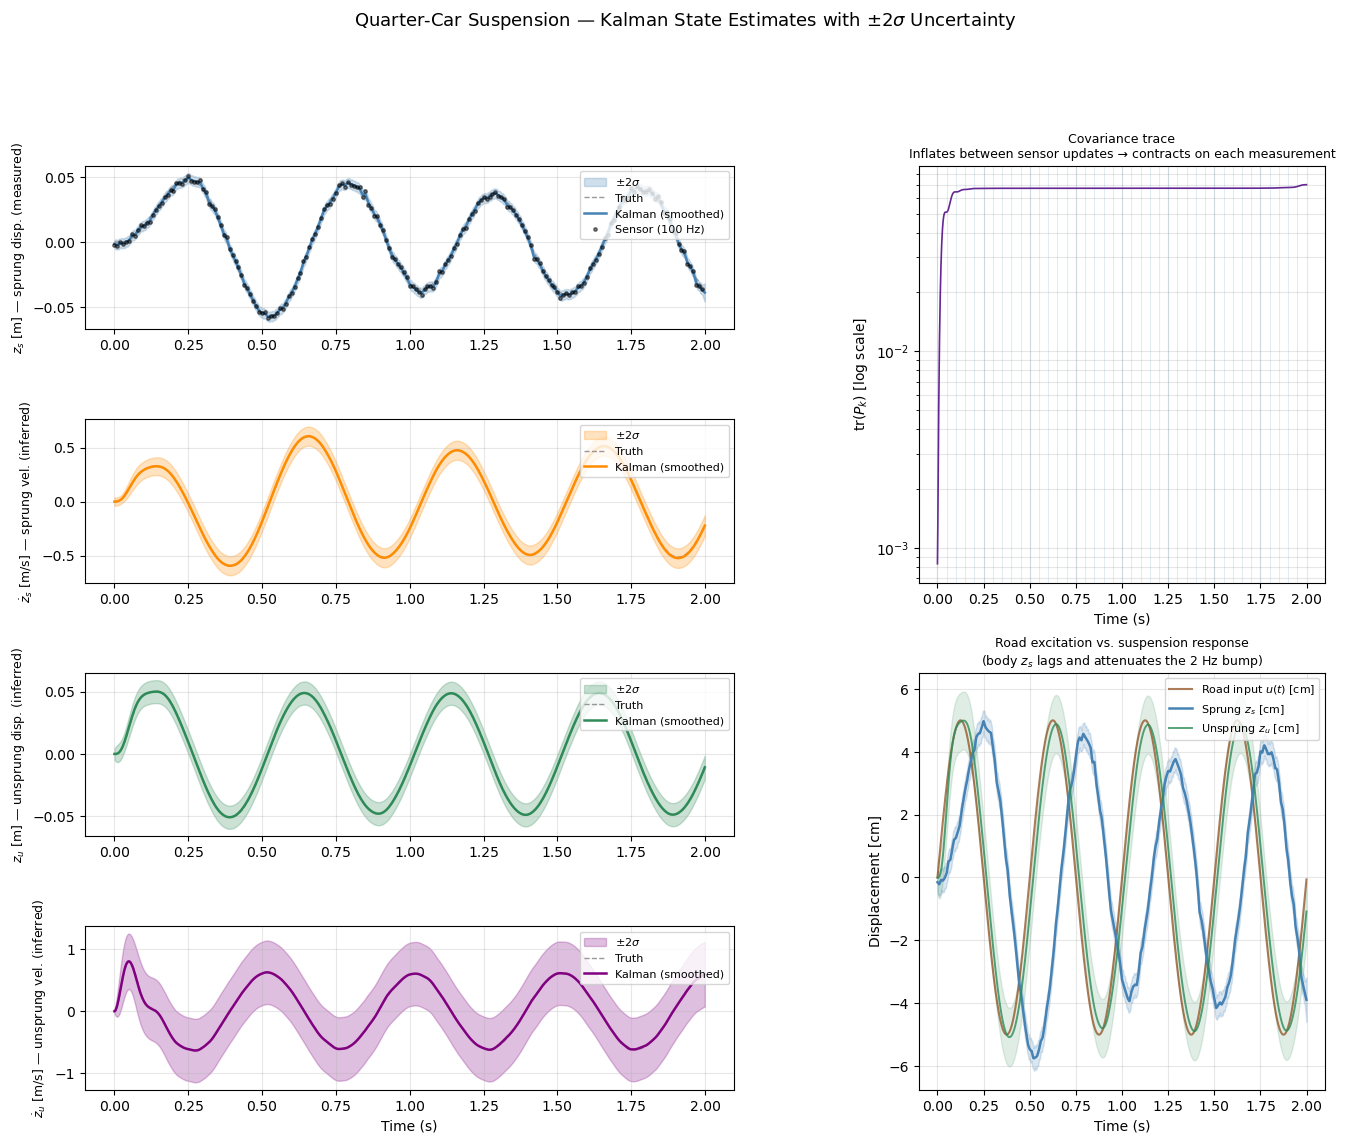

Chrono summary:
    #   label                               t          ΔT
  ───   ─────────────────────────   ─────────   ─────────
    1.  Model initialized              1.0 ms      1.0 ms
    2.  Sampling completed            17.8 ms     16.8 ms
    3.  Multi-rate input prepared     17.9 ms      0.1 ms
    4.  Filtering completed          137.1 ms    119.1 ms
  ───   ─────────────────────────   ─────────   ─────────
        total                        509.5 ms


In [5]:
from kalman.apps.suspensions import SuspensionModel
from kalman.helpers import get_canvas, make_multirate_input
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

# ------------------------------------------------------------------
# Time setup
# ------------------------------------------------------------------
fs_ekf    = 1000.0
fs_sensor = 100.0
T         = 2.0
t_ekf     = np.arange(int(T * fs_ekf)) / fs_ekf
u_road    = 0.05 * np.sin(2 * np.pi * 2.0 * t_ekf)   # 2 Hz bump, 5 cm

# ------------------------------------------------------------------
# Model + filter
# ------------------------------------------------------------------
chrono.restart()
suspension = SuspensionModel("chassis",
                             m_s=300, m_u=50,
                             k_s=20_000, b_s=1_500, k_t=180_000,
                             measurement_uncertainty=0.002,
                             process_uncertainty=0.001,
                             fs=fs_ekf)
suspension.initial_state([0, 0, 0, 0])
suspension.print()
chrono.lap("Model initialized")

sample = suspension.sample(T, uk=u_road.reshape(-1, 1))
chrono.lap("Sampling completed")

z_sensor    = sample.zk[::int(fs_ekf / fs_sensor)]
z_multirate = make_multirate_input([(z_sensor, fs_sensor)], base_fs=fs_ekf)
chrono.lap("Multi-rate input prepared")

record = suspension.filter(z_multirate, uk=u_road.reshape(-1, 1),
                           smooth=True, reset=True)
chrono.lap("Filtering completed")

# ------------------------------------------------------------------
# Extract estimates and uncertainty (±2σ diagonal of Pk)
# ------------------------------------------------------------------
xk  = record.xk    # (N, 4): [z_s, ż_s, z_u, ż_u]
Pk  = record.Pk    # (N, 4, 4)
sig = 2.0 * np.sqrt(np.diagonal(Pk, axis1=1, axis2=2))   # (N, 4)  ±2σ
xk_true = sample.xk   # truth

# Sensor fire mask: rows in z_multirate that are not NaN
sensor_mask = ~np.isnan(z_multirate[:, 0])
t_sens_fire = t_ekf[sensor_mask]
z_sens_vals = z_multirate[sensor_mask, 0]   # actual noisy sensor readings

# Covariance trace over time
trace_P = np.trace(Pk, axis1=1, axis2=2)

# ------------------------------------------------------------------
# Figure: 4 state estimates (left) + covariance + road overlay (right)
# ------------------------------------------------------------------
COLORS = ["steelblue", "darkorange", "seagreen", "purple"]
LABELS = [r"$z_s$ [m] — sprung disp. (measured)",
          r"$\dot{z}_s$ [m/s] — sprung vel. (inferred)",
          r"$z_u$ [m] — unsprung disp. (inferred)",
          r"$\dot{z}_u$ [m/s] — unsprung vel. (inferred)"]

fig = plt.figure(figsize=(16, 12))
gs  = gridspec.GridSpec(4, 2, figure=fig, hspace=0.55, wspace=0.35,
                        width_ratios=[1.6, 1])

for i in range(4):
    ax = fig.add_subplot(gs[i, 0])
    # ±2σ uncertainty band
    ax.fill_between(t_ekf,
                    xk[:, i] - sig[:, i], xk[:, i] + sig[:, i],
                    alpha=0.25, color=COLORS[i], label=r"$\pm 2\sigma$")
    # Truth (thin dashed)
    ax.plot(t_ekf, xk_true[:, i], '--', lw=1.0, color="gray", alpha=0.8, label="Truth")
    # Kalman smoothed estimate
    ax.plot(t_ekf, xk[:, i], lw=1.8, color=COLORS[i], label="Kalman (smoothed)")
    # Sensor scatter for directly measured state
    if i == 0:
        ax.scatter(t_sens_fire, z_sens_vals, s=6, color="black",
                   alpha=0.5, zorder=5, label=f"Sensor ({int(fs_sensor)} Hz)")
    ax.set_xlabel("Time (s)" if i == 3 else "")
    ax.set_ylabel(LABELS[i], fontsize=9)
    ax.legend(fontsize=8, loc="upper right")
    ax.grid(True, alpha=0.3)

# --- Covariance trace: shows inflate (predict) / contract (update) cycle ---
ax_cov = fig.add_subplot(gs[0:2, 1])
ax_cov.semilogy(t_ekf, trace_P, color="indigo", lw=1.2, alpha=0.85)
ax_cov.set_xlabel("Time (s)")
ax_cov.set_ylabel(r"tr($P_k$) [log scale]")
ax_cov.set_title("Covariance trace\nInflates between sensor updates → contracts on each measurement",
                 fontsize=9)
ax_cov.grid(True, alpha=0.3, which="both")
# Overlay sensor fire times as vertical ticks
for ts in t_sens_fire[::5]:
    ax_cov.axvline(ts, color="steelblue", alpha=0.15, lw=0.8)

# --- Road input vs sprung response ---
ax_road = fig.add_subplot(gs[2:, 1])
ax_road.plot(t_ekf, u_road * 100, color="saddlebrown", lw=1.5,
             alpha=0.7, label="Road input $u(t)$ [cm]")
ax_road.plot(t_ekf, xk[:, 0] * 100, color="steelblue", lw=1.8,
             label=r"Sprung $z_s$ [cm]")
ax_road.fill_between(t_ekf,
                     (xk[:, 0] - sig[:, 0]) * 100,
                     (xk[:, 0] + sig[:, 0]) * 100,
                     alpha=0.2, color="steelblue")
ax_road.plot(t_ekf, xk[:, 2] * 100, color="seagreen", lw=1.4,
             alpha=0.8, label=r"Unsprung $z_u$ [cm]")
ax_road.fill_between(t_ekf,
                     (xk[:, 2] - sig[:, 2]) * 100,
                     (xk[:, 2] + sig[:, 2]) * 100,
                     alpha=0.15, color="seagreen")
ax_road.set_xlabel("Time (s)")
ax_road.set_ylabel("Displacement [cm]")
ax_road.set_title("Road excitation vs. suspension response\n"
                  r"(body $z_s$ lags and attenuates the 2 Hz bump)", fontsize=9)
ax_road.legend(fontsize=8)
ax_road.grid(True, alpha=0.3)

fig.suptitle("Quarter-Car Suspension — Kalman State Estimates with $\\pm 2\\sigma$ Uncertainty",
             fontsize=13, y=1.01)
plt.show()
chrono.summary()

### Interpreting the results

| State | Source | Key point |
|---|---|---|
| $z_s$ | directly measured (100 Hz) | KF interpolates at 1 kHz; smoother removes update ripple |
| $\dot{z}_s$ | inferred | velocity from position-only sensor — state reconstruction |
| $z_u$ | inferred | wheel hub never measured; observable via spring/damper coupling |
| $\dot{z}_u$ | inferred | same |

The covariance **inflates** between sensor updates (predict-only) and **contracts** at each  
measurement — visible as the sawtooth in tr($P_k$).  Sprung displacement ($z_s$) tracks the  
2 Hz road bump while the unsprung mass follows with reduced amplitude (suspension isolation).

## Section 2 — Fiber Thermal Noise: Violin Modes + Power-Line Subtraction

Precision suspension fibers (GW detectors, optical clocks) contribute two classes of  
narrow spectral lines to the measurement noise:

| Source | Model | Frequencies (KAGRA-like) | Q factor |
|---|---|---|---|
| **Violin modes** — thermal resonance of fiber | `InharmonicOscillatorModel(B>0)` | 180, 420, 750 Hz | $\sim 10^4$ |
| **Power-line harmonics** — AC electrical coupling | `InharmonicOscillatorModel(B=0)` | 60, 120, 180, 240 Hz | $\sim 10^3$ |

Both are tracked as slowly-varying complex envelopes in rotating frames via  
the **Hilbert + demodulation** preprocess (one frame per partial).  
A single real $(N,1)$ strain signal is broadcast to all sub-models automatically.

### Extraction pipeline

```
strain  →  [violin model]  →  strain − violin modes
        →  [power-grid model]  →  clean strain
```

The two models are independent and applied sequentially.  At 180 Hz, violin mode 1  
and power-line harmonic 3 overlap to within 0.1 Hz; the models resolve them by their  
very different $Q$ values ($\Delta f_{\rm violin} \approx 0.014$ Hz vs  
$\Delta f_{\rm PG} \approx 0.22$ Hz).

Violin partials  : [184.42 393.59 647.57] Hz  (B=0.0485)
Power-grid lines : [ 60. 120. 180. 240.] Hz

Detector noise ASD at 100 Hz : 1.76e-20 1/sqrt(Hz)
Detector noise RMS           : 1.55e-18

PG suppression:
     60 Hz: raw=4.57e-19  clean=1.22e-20  +31.5 dB  [above NF]
    120 Hz: raw=2.51e-19  clean=4.21e-21  +35.5 dB  [above NF]
    180 Hz: raw=1.16e-19  clean=5.19e-21  +27.0 dB  [above NF]
    240 Hz: raw=5.53e-20  clean=3.67e-21  +23.5 dB  [above NF]


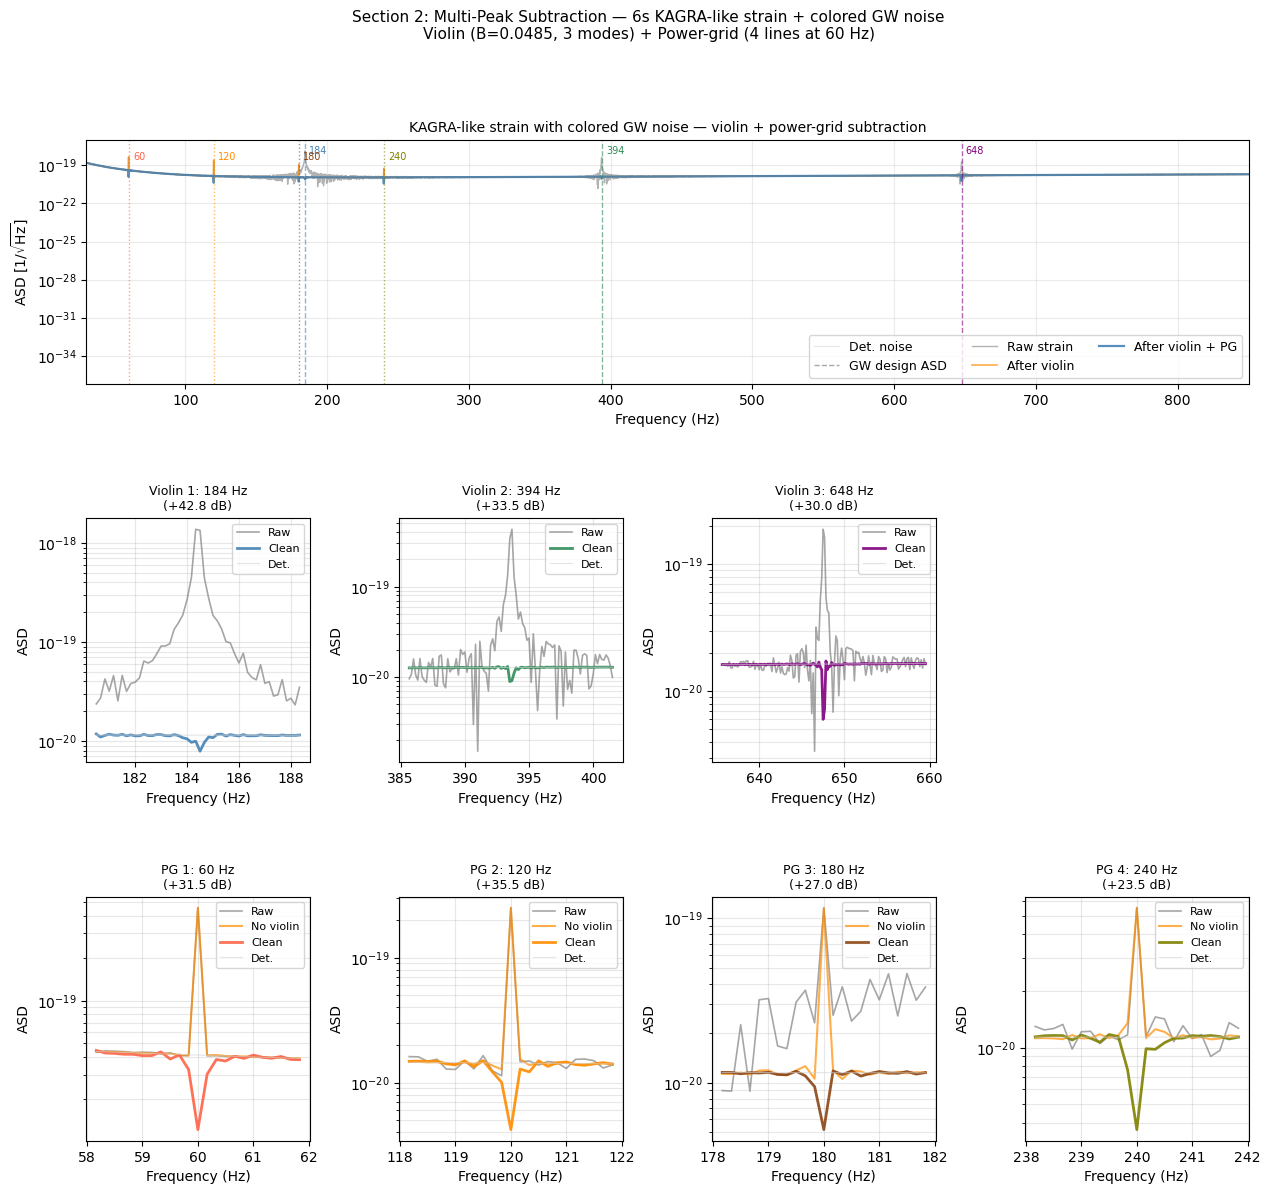

Chrono summary:
    #   label                                  t          ΔT
  ───   ────────────────────────────   ─────────   ─────────
    1.  Violin modes removed             3.806 s     3.806 s
    2.  Power-line harmonics removed     8.213 s     4.407 s
  ───   ────────────────────────────   ─────────   ─────────
        total                            8.865 s


In [6]:
from kalman.apps.oscillators import InharmonicOscillatorModel
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from numpy.fft import rfft, rfftfreq, irfft

# ------------------------------------------------------------------
# Helpers
# ------------------------------------------------------------------
def gw_asd(f):
    """Simplified GW detector noise ASD [1/sqrt(Hz)] — aLIGO-like."""
    f = np.asarray(f, float)
    floor = 1e-20
    f_eff = np.maximum(f, 20.0)                        # seismic wall at 20 Hz
    thermal = floor * (120.0 / f_eff)**2               # thermal 1/f² rise
    quantum = floor * np.sqrt(1 + (f_eff / 500.0)**2)  # quantum noise floor
    return np.sqrt(thermal**2 + quantum**2)

def colored_noise(N, fs, asd_func):
    """Generate a noise realization with the given one-sided ASD."""
    freqs = rfftfreq(N, 1.0/fs)
    freqs_safe = np.where(freqs > 0, freqs, freqs[1])
    amp   = asd_func(freqs_safe) * np.sqrt(N * fs) / 2.0
    fft_n = amp * np.exp(1j * np.random.uniform(0, 2*np.pi, len(freqs)))
    fft_n[0] = 0.0
    return irfft(fft_n, n=N)

def reconstruct(model, rec):
    """Reconstruct real lab-frame signal from sampled rotating-frame states."""
    t = np.arange(len(rec.xk)) / model.fs
    return sum(
        rec.xk[:, 2*i] * np.cos(sub["wc"]*t) - rec.xk[:, 2*i+1] * np.sin(sub["wc"]*t)
        for i, sub in enumerate(model.models)
    )

# ------------------------------------------------------------------
# Model parameters
# ------------------------------------------------------------------
fs, T = 4096.0, 6.0
N = int(T * fs)

f0_v, B_v = 180.10, 0.0485
Q_v = [1.3e4, 1.8e4, 2.1e4]
A_v = [1.0e-18, 3.0e-19, 1.5e-19]

f0_pg, n_pg = 60.0, 4
Q_pg = [1e5, 5e4, 3e4, 2e4]
A_pg = [2.0e-19, 1.0e-19, 5.0e-20, 3.0e-20]

noise_rms = 5e-19   # approximate detector noise RMS for filter tuning

freqs_v  = InharmonicOscillatorModel.partial_frequencies(f0_v, B_v, 3)
freqs_pg = InharmonicOscillatorModel.partial_frequencies(f0_pg, 0.0, n_pg)
print(f"Violin partials  : {np.round(freqs_v, 2)} Hz  (B={B_v})")
print(f"Power-grid lines : {np.round(freqs_pg, 1)} Hz")

# ------------------------------------------------------------------
# Build models  (before sampling)
# ------------------------------------------------------------------
violin_model = InharmonicOscillatorModel(
    'violin', f0=f0_v, n_harmonics=3, B=B_v, fs=fs,
    Q_factor=Q_v, measurement_uncertainty=noise_rms * 2.0, process_uncertainty=1e-26,
)
for m, A in zip(violin_model.models, A_v): m.initial_state([A, 0.0])
violin_model.initial_state(np.vstack([m.x0 for m in violin_model.models]))

pg_model = InharmonicOscillatorModel(
    'powergrid', f0=f0_pg, n_harmonics=n_pg, B=0.0, fs=fs,
    Q_factor=Q_pg, measurement_uncertainty=noise_rms * 2.0, process_uncertainty=1e-26,
)
for m, A in zip(pg_model.models, A_pg): m.initial_state([A, 0.0])
pg_model.initial_state(np.vstack([m.x0 for m in pg_model.models]))

# ------------------------------------------------------------------
# Signal generation: sampler (modes) + colored GW noise
# ------------------------------------------------------------------
np.random.seed(42)
violin_signal = reconstruct(violin_model, violin_model.sample(T, measurement_noise=False))
pg_signal     = reconstruct(pg_model,     pg_model.sample(T, measurement_noise=False))
detector_noise = colored_noise(N, fs, gw_asd)
strain = violin_signal + pg_signal + detector_noise
t = np.arange(N) / fs

noise_asd_at_100hz = gw_asd(100.0)
print(f"\nDetector noise ASD at 100 Hz : {noise_asd_at_100hz:.2e} 1/sqrt(Hz)")
print(f"Detector noise RMS           : {np.sqrt(np.mean(detector_noise**2)):.2e}")

# ------------------------------------------------------------------
# Step 1 — subtract violin modes
# ------------------------------------------------------------------
chrono.restart()
record_v = violin_model.filter(strain.reshape(-1, 1), smooth=True, reset=True)
violins, strain_no_v = violin_model.extract(record_v, strain)
chrono.lap("Violin modes removed")

# ------------------------------------------------------------------
# Step 2 — subtract power-line harmonics from residual
# ------------------------------------------------------------------
record_pg = pg_model.filter(strain_no_v.reshape(-1, 1), smooth=True, reset=True)
pg_lines, strain_clean = pg_model.extract(record_pg, strain_no_v)
chrono.lap("Power-line harmonics removed")

# ------------------------------------------------------------------
# ASD
# ------------------------------------------------------------------
freqs_f = rfftfreq(N, 1/fs)
norm    = 2 / np.sqrt(fs * N)
S_raw   = np.abs(rfft(strain))          * norm
S_no_v  = np.abs(rfft(strain_no_v))    * norm
S_clean = np.abs(rfft(strain_clean))   * norm
S_det   = np.abs(rfft(detector_noise)) * norm
S_design = gw_asd(np.maximum(freqs_f, 1.0))

print("\nPG suppression:")
noise_level = np.median(S_det)
for fn in freqs_pg:
    idx = np.argmin(np.abs(freqs_f - fn))
    r, c = S_raw[idx], S_clean[idx]
    db = 20*np.log10(r/c) if c > 0 else float('inf')
    print(f"  {fn:5.0f} Hz: raw={r:.2e}  clean={c:.2e}  {db:+.1f} dB  [{'above NF' if r>noise_level else 'below NF'}]")

# ------------------------------------------------------------------
# Figure: full ASD (top) + violin zooms + PG zooms
# ------------------------------------------------------------------
fig = plt.figure(figsize=(15, 13))
gs  = gridspec.GridSpec(3, 4, figure=fig, hspace=0.55, wspace=0.4)

ax0 = fig.add_subplot(gs[0, :])
ax0.semilogy(freqs_f, S_det,     color='lightgray',  lw=0.8, alpha=0.5, label='Det. noise')
ax0.semilogy(freqs_f, S_design,  color='black',      lw=1.0, ls='--', alpha=0.35, label='GW design ASD')
ax0.semilogy(freqs_f, S_raw,     color='gray',       lw=1.0, alpha=0.6, label='Raw strain')
ax0.semilogy(freqs_f, S_no_v,    color='darkorange', lw=1.2, alpha=0.7, label='After violin')
ax0.semilogy(freqs_f, S_clean,   color='steelblue',  lw=1.6, alpha=0.9, label='After violin + PG')
colors_v  = ['steelblue', 'seagreen', 'purple']
colors_pg = ['tomato', 'darkorange', 'saddlebrown', 'olive']
for fn, col in zip(freqs_v, colors_v):
    ax0.axvline(fn, ls='--', color=col, lw=1.0, alpha=0.6)
    ax0.text(fn+3, S_raw.max()*0.6, f'{fn:.0f}', fontsize=7, color=col)
for fn, col in zip(freqs_pg, colors_pg):
    ax0.axvline(fn, ls=':', color=col, lw=1.0, alpha=0.6)
    ax0.text(fn+3, S_raw.max()*0.2, f'{fn:.0f}', fontsize=7, color=col)
ax0.set_xlim(30, 850)
ax0.set_xlabel('Frequency (Hz)'); ax0.set_ylabel(r'ASD [1/$\sqrt{\mathrm{Hz}}$]')
ax0.set_title('KAGRA-like strain with colored GW noise — violin + power-grid subtraction', fontsize=10)
ax0.legend(fontsize=9, ncol=3); ax0.grid(True, alpha=0.25, which='both')

v_bws = [4.0, 8.0, 12.0]
for col_idx, (fn, bw, col) in enumerate(zip(freqs_v, v_bws, colors_v)):
    ax = fig.add_subplot(gs[1, col_idx])
    msk = (freqs_f > fn-bw) & (freqs_f < fn+bw)
    ax.semilogy(freqs_f[msk], S_raw[msk],   color='gray', lw=1.2, alpha=0.7, label='Raw')
    ax.semilogy(freqs_f[msk], S_clean[msk], color=col,   lw=2.0, alpha=0.9, label='Clean')
    ax.semilogy(freqs_f[msk], S_det[msk],   color='lightgray', lw=0.8, alpha=0.6, label='Det.')
    idx = np.argmin(np.abs(freqs_f - fn))
    db_v = 20*np.log10(S_raw[idx]/S_clean[idx]) if S_clean[idx]>0 else float('inf')
    ax.set_title(f'Violin {col_idx+1}: {fn:.0f} Hz\n({db_v:+.1f} dB)', fontsize=9)
    ax.set_xlabel('Frequency (Hz)'); ax.set_ylabel('ASD')
    ax.legend(fontsize=8); ax.grid(True, alpha=0.3, which='both')

pg_bw = 2.0
for col_idx, (fn, col) in enumerate(zip(freqs_pg, colors_pg)):
    ax = fig.add_subplot(gs[2, col_idx])
    msk = (freqs_f > fn-pg_bw) & (freqs_f < fn+pg_bw)
    ax.semilogy(freqs_f[msk], S_raw[msk],  color='gray',        lw=1.2, alpha=0.7, label='Raw')
    ax.semilogy(freqs_f[msk], S_no_v[msk], color='darkorange',  lw=1.5, alpha=0.7, label='No violin')
    ax.semilogy(freqs_f[msk], S_clean[msk],color=col,           lw=2.0, alpha=0.9, label='Clean')
    ax.semilogy(freqs_f[msk], S_det[msk],  color='lightgray',   lw=0.8, alpha=0.6, label='Det.')
    idx = np.argmin(np.abs(freqs_f - fn))
    r, c = S_raw[idx], S_clean[idx]
    db_pg = 20*np.log10(r/c) if c>0 else float('inf')
    snr_ok = r > noise_level
    ax.set_title(f'PG {col_idx+1}: {fn:.0f} Hz\n({db_pg:+.1f} dB)' if snr_ok else
                 f'PG {col_idx+1}: {fn:.0f} Hz\n(below NF)', fontsize=9)
    ax.set_xlabel('Frequency (Hz)'); ax.set_ylabel('ASD')
    ax.legend(fontsize=8); ax.grid(True, alpha=0.3, which='both')

fig.suptitle(
    f'Section 2: Multi-Peak Subtraction — {int(T)}s KAGRA-like strain + colored GW noise\n'
    f'Violin (B={B_v}, {len(freqs_v)} modes) + Power-grid ({n_pg} lines at {int(f0_pg)} Hz)',
    fontsize=11)
plt.show()
chrono.summary()


## Possible Improvements & Extensions

**Quarter-car (Section 1)**
- Add wheel-hub accelerometer to make $z_u$ directly observable
- Variable damper control: use the Kalman estimate to drive an active suspension
- Half-car / full-car model: add pitch DOF → 6-state system

**Fiber thermal noise (Section 2)**
- Per-mode $Q$ estimation: augment the state with $\Delta\omega_n$ (frequency drift) and run an EKF
- Real detector data: replace the synthetic strain with `gwpy` frames from GWOSC
- Simultaneous fit of $f_0$ and $B$: use `InharmonicOscillatorModel.fit_inharmonicity()` on an ASD segment
- KAGRA has 4 fibers per mirror — run one `InharmonicOscillatorModel` per fiber, subtract independently